# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

print("Бібліотеки успішно імпортовано!")


Бібліотеки успішно імпортовано!


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:

# Завантаження набору даних Iris
iris = load_iris()

# Створення таблиці
df_iris = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Виведення перших п'яти рядків
df_iris.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

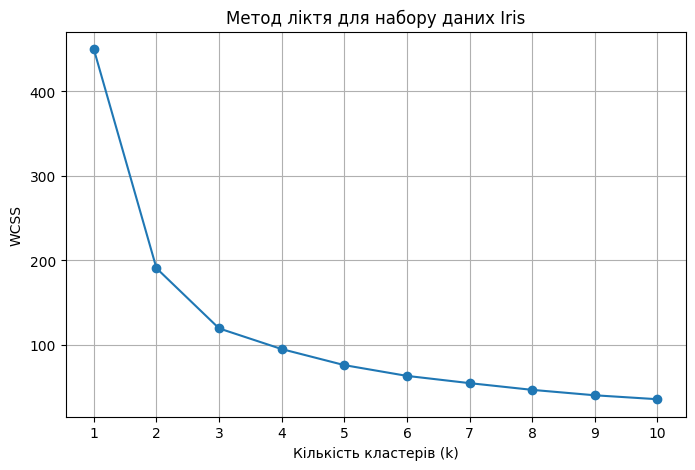

In [3]:

# Використовуємо перші три ознаки Iris
X = df_iris.iloc[:, :3]

# Стандартизація даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Обчислення WCSS для різної кількості кластерів
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Побудова графіка методу ліктя
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Метод ліктя для набору даних Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

Кількість кластерів: 2, Silhouette Score: 0.5525
Кількість кластерів: 3, Silhouette Score: 0.4594
Кількість кластерів: 4, Silhouette Score: 0.4057
Кількість кластерів: 5, Silhouette Score: 0.3755
Кількість кластерів: 6, Silhouette Score: 0.3772
Кількість кластерів: 7, Silhouette Score: 0.3628
Кількість кластерів: 8, Silhouette Score: 0.3814
Кількість кластерів: 9, Silhouette Score: 0.3749
Кількість кластерів: 10, Silhouette Score: 0.3791


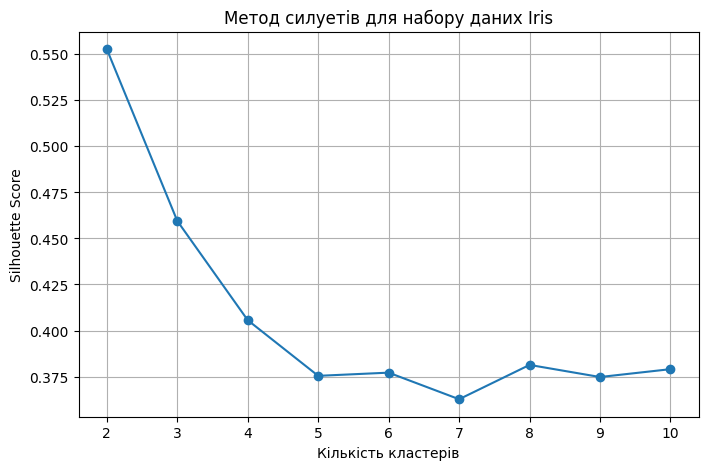

In [4]:

# Обчислення коефіцієнта силуета
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f'Кількість кластерів: {k}, Silhouette Score: {score:.4f}')

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Метод силуетів для набору даних Iris')
plt.xlabel('Кількість кластерів')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

Кількість кластерів: 2
Координати центрів кластерів:
[[ 0.50728948 -0.42663134  0.65249366]
 [-1.01457897  0.85326268 -1.30498732]]


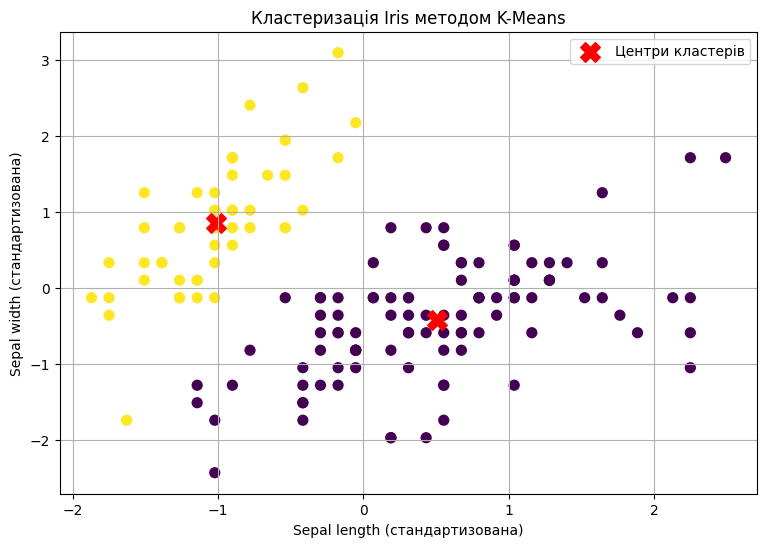

In [5]:

# Створення моделі K-Means з двома кластерами
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Навчання моделі
clusters = kmeans_final.fit_predict(X_scaled)

# Отримання центрів кластерів
centers = kmeans_final.cluster_centers_

print("Кількість кластерів:", len(set(clusters)))
print("Координати центрів кластерів:")
print(centers)

# Візуалізація кластерів
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Центри кластерів'
)

plt.title('Кластеризація Iris методом K-Means')
plt.xlabel('Sepal length (стандартизована)')
plt.ylabel('Sepal width (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()


**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Бібліотеки для класифікації успішно імпортовано!")


Бібліотеки для класифікації успішно імпортовано!


**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [30]:

!pip install -q kagglehub

import kagglehub
import glob
import os

path = kagglehub.dataset_download(
    "rabieelkharoua/students-performance-dataset"
)

print("Шлях до набору даних:", path)

csv_files = glob.glob(os.path.join(path, "*.csv"))

print("Знайдені CSV-файли:")
for file in csv_files:
    print(os.path.basename(file))

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Шлях до набору даних: /kaggle/input/students-performance-dataset
Знайдені CSV-файли:
Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [31]:

# Завантаження CSV-файлу
df = pd.read_csv(csv_files[0])

# Виведення перших п'яти рядків
df.head()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [32]:

# Виведення назв усіх стовпців
print("Назви стовпців:")
print(df.columns.tolist())


Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [33]:

# Інформація про структуру таблиці
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [34]:

# Перевірка пропущених значень
print("Кількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:")
print(df.isnull().sum().sum())


Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Загальна кількість пропущених значень:
0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [35]:

# Підрахунок дублікатів
duplicates = df.duplicated().sum()

print("Кількість дублікатів:", duplicates)


Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [36]:

# Основні описові статистики
df.describe()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [37]:

# Формування ознак X
X = df.drop(columns=['GradeClass', 'StudentID'])

# Формування цільової змінної y
y = df['GradeClass']

# Поділ на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Стандартизація ознак
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("Підготовку даних завершено!")


Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)
Підготовку даних завершено!


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [38]:

# Створення моделі Random Forest
rf = RandomForestClassifier(random_state=42)

# Сітка параметрів
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Підбір параметрів
rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

# Найкраща модель
rf_best = rf_grid.best_estimator_

# Прогнозування
rf_pred = rf_best.predict(X_test_scaled)

# Результати
rf_cv = rf_grid.best_score_
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest")
print("Найкращі параметри:", rf_grid.best_params_)
print("Середня CV-точність:", round(rf_cv, 4))
print("Тестова Accuracy:", round(rf_accuracy, 4))


Random Forest
Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова Accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [39]:

# Створення моделі логістичної регресії
lr = LogisticRegression(
    solver='saga',
    max_iter=5000,
    random_state=42
)

# Сітка параметрів
lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2']
}

# Підбір параметрів
lr_grid = GridSearchCV(
    lr,
    lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

# Найкраща модель
lr_best = lr_grid.best_estimator_

# Прогнозування
lr_pred = lr_best.predict(X_test_scaled)

# Результати
lr_cv = lr_grid.best_score_
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression")
print("Найкращі параметри:", lr_grid.best_params_)
print("Середня CV-точність:", round(lr_cv, 4))
print("Тестова Accuracy:", round(lr_accuracy, 4))


Logistic Regression
Найкращі параметри: {'C': 10, 'penalty': 'l2'}
Середня CV-точність: 0.7951
Тестова Accuracy: 0.7933


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [40]:

# Створення моделі SVM
svm = SVC()

# Сітка параметрів
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# Підбір параметрів
svm_grid = GridSearchCV(
    svm,
    svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

# Найкраща модель
svm_best = svm_grid.best_estimator_

# Прогнозування
svm_pred = svm_best.predict(X_test_scaled)

# Результати
svm_cv = svm_grid.best_score_
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Support Vector Machine")
print("Найкращі параметри:", svm_grid.best_params_)
print("Середня CV-точність:", round(svm_cv, 4))
print("Тестова Accuracy:", round(svm_accuracy, 4))


Support Vector Machine
Найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова Accuracy: 0.858


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [41]:

# Створення таблиці результатів
results = pd.DataFrame({
    'Модель': [
        'Random Forest',
        'Logistic Regression',
        'SVM'
    ],
    'CV Accuracy': [
        rf_cv,
        lr_cv,
        svm_cv
    ],
    'Test Accuracy': [
        rf_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

print("Порівняння моделей:")
display(results)

# Вибір найкращої моделі за CV-точністю
best_model_name = results.loc[
    results['CV Accuracy'].idxmax(),
    'Модель'
]

print("\nНайкраща модель за CV-точністю:", best_model_name)

# Вибір прогнозів найкращої моделі
predictions = {
    'Random Forest': rf_pred,
    'Logistic Regression': lr_pred,
    'SVM': svm_pred
}

best_predictions = predictions[best_model_name]

# Звіт класифікації
print("\nClassification Report:")
print(classification_report(y_test, best_predictions))


Порівняння моделей:


,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.921071,0.910230
1,Logistic Regression,0.795084,0.793319
2,SVM,0.852065,0.858038



Найкраща модель за CV-точністю: Random Forest

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

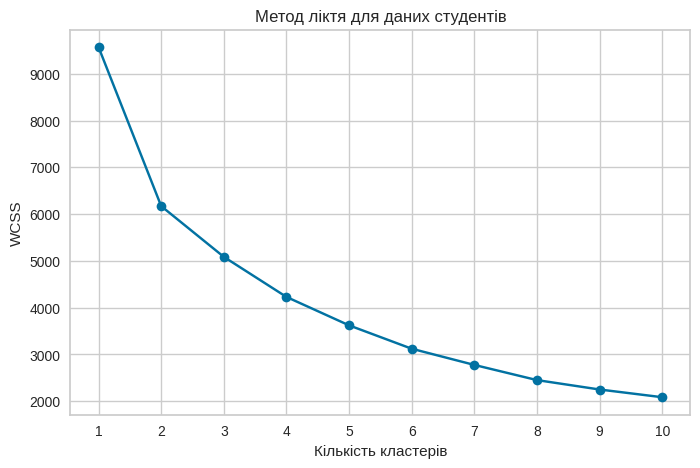

In [42]:

# Вибір чотирьох ознак
X_students = df[
    ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
]

# Стандартизація даних
scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(X_students)

# Обчислення WCSS
wcss_students = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_students_scaled)
    wcss_students.append(kmeans.inertia_)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_students, marker='o')

plt.title('Метод ліктя для даних студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

Кількість кластерів: 2, Silhouette Score: 0.3080
Кількість кластерів: 3, Silhouette Score: 0.2702
Кількість кластерів: 4, Silhouette Score: 0.2580
Кількість кластерів: 5, Silhouette Score: 0.2645
Кількість кластерів: 6, Silhouette Score: 0.2689
Кількість кластерів: 7, Silhouette Score: 0.2692
Кількість кластерів: 8, Silhouette Score: 0.2712
Кількість кластерів: 9, Silhouette Score: 0.2732
Кількість кластерів: 10, Silhouette Score: 0.2725


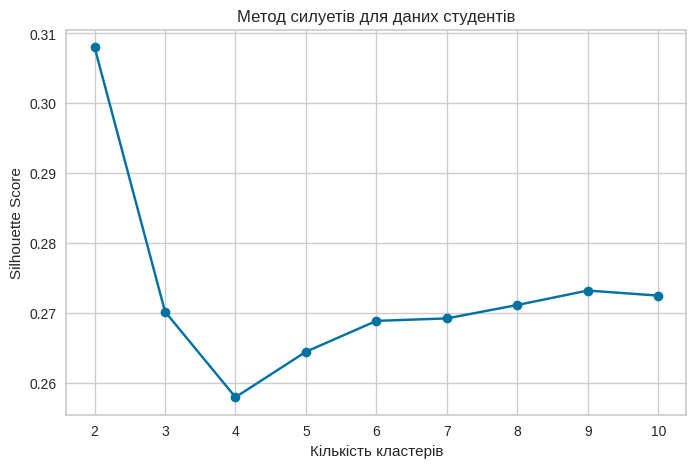

In [43]:

# Обчислення коефіцієнтів силуета
silhouette_students = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_students_scaled)

    score = silhouette_score(
        X_students_scaled,
        labels
    )

    silhouette_students.append(score)

    print(
        f'Кількість кластерів: {k}, '
        f'Silhouette Score: {score:.4f}'
    )

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_students,
    marker='o'
)

plt.title('Метод силуетів для даних студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [44]:

!pip install -q kneed yellowbrick

print("Додаткові бібліотеки встановлено!")


Додаткові бібліотеки встановлено!


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [45]:

import numpy as np

from sklearn.decomposition import PCA
from kneed import KneeLocator

print("PCA та KneeLocator успішно імпортовано!")


PCA та KneeLocator успішно імпортовано!


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [46]:

# Видалення ідентифікатора та цільової змінної
X_pca = df.drop(
    columns=['StudentID', 'GradeClass']
)

# Перевірка даних
print("Розмір набору даних для PCA:", X_pca.shape)

print("\nПерші п'ять рядків:")
display(X_pca.head())


Розмір набору даних для PCA: (2392, 13)

Перші п'ять рядків:


,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196
1,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915
2,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602
3,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218
4,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [47]:

# Стандартизація всіх ознак
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

# Створення та навчання PCA
pca = PCA()
pca.fit(X_pca_scaled)

# Частка поясненої дисперсії
explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")

for i, value in enumerate(explained_variance, start=1):
    print(f"Компонента {i}: {value:.4f}")


Частка поясненої дисперсії кожної компоненти:
Компонента 1: 0.1525
Компонента 2: 0.0861
Компонента 3: 0.0827
Компонента 4: 0.0807
Компонента 5: 0.0786
Компонента 6: 0.0779
Компонента 7: 0.0763
Компонента 8: 0.0760
Компонента 9: 0.0744
Компонента 10: 0.0738
Компонента 11: 0.0717
Компонента 12: 0.0675
Компонента 13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент: 2


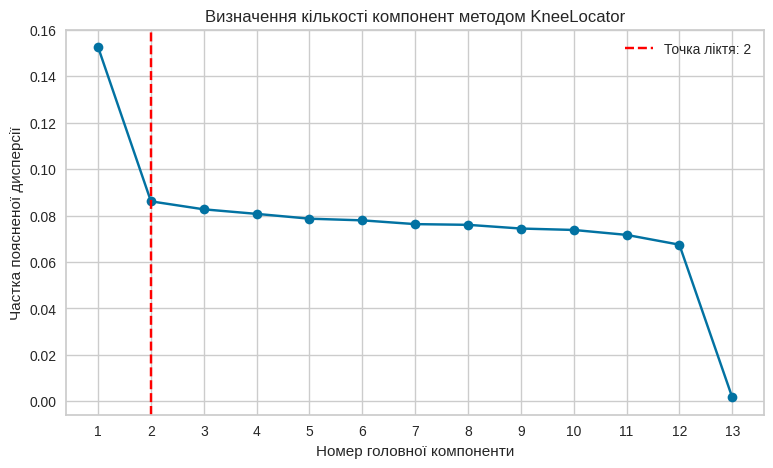

In [48]:

# Номери головних компонент
components = np.arange(1, len(explained_variance) + 1)

# Пошук точки ліктя
knee_locator = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

optimal_components = knee_locator.knee

print("Оптимальна кількість компонент:", optimal_components)

# Побудова графіка
plt.figure(figsize=(9, 5))

plt.plot(
    components,
    explained_variance,
    marker='o'
)

if optimal_components is not None:
    plt.axvline(
        x=optimal_components,
        color='red',
        linestyle='--',
        label=f'Точка ліктя: {optimal_components}'
    )
    plt.legend()

plt.title('Визначення кількості компонент методом KneeLocator')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components)
plt.grid(True)
plt.show()


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Обрана кількість головних компонент: 2
Кумулятивна пояснена дисперсія: 0.2386
У відсотках: 23.86 %


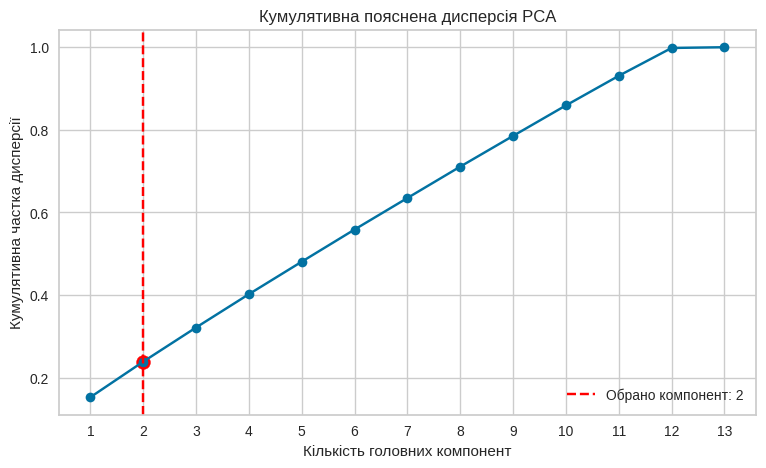

Розмір даних після PCA: (2392, 2)


In [49]:

# Обчислення кумулятивної дисперсії
cumulative_variance = np.cumsum(explained_variance)

# Якщо точку ліктя не знайдено,
# вибираємо мінімальну кількість компонент,
# яка пояснює не менше 90% дисперсії
if optimal_components is None:
    optimal_components = np.argmax(
        cumulative_variance >= 0.90
    ) + 1

print("Обрана кількість головних компонент:", optimal_components)

# Фактична пояснена дисперсія
selected_variance = cumulative_variance[optimal_components - 1]

print(
    "Кумулятивна пояснена дисперсія:",
    round(selected_variance, 4)
)

print(
    "У відсотках:",
    round(selected_variance * 100, 2), "%"
)

# Побудова графіка
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axvline(
    x=optimal_components,
    color='red',
    linestyle='--',
    label=f'Обрано компонент: {optimal_components}'
)

plt.scatter(
    optimal_components,
    selected_variance,
    color='red',
    s=100
)

plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)
plt.show()

# Перетворення даних через PCA
pca_final = PCA(n_components=optimal_components)

X_pca_transformed = pca_final.fit_transform(
    X_pca_scaled
)

print("Розмір даних після PCA:", X_pca_transformed.shape)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [50]:

from yellowbrick.cluster import KElbowVisualizer

print("KElbowVisualizer успішно імпортовано!")


KElbowVisualizer успішно імпортовано!


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

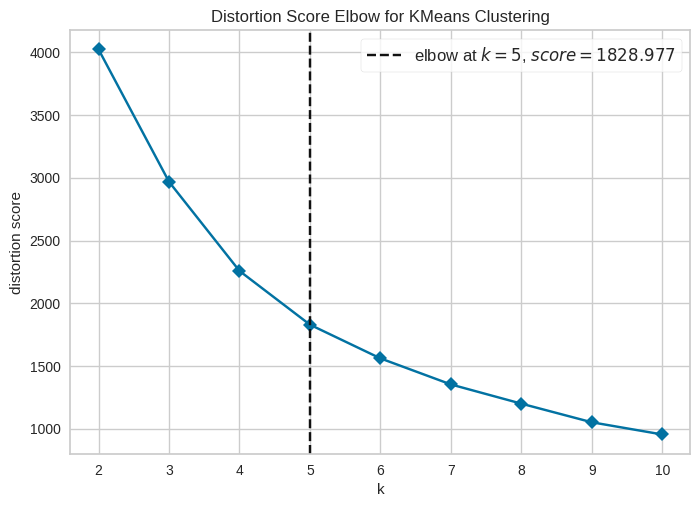

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [51]:

# Створення моделі K-Means
model = KMeans(
    random_state=42,
    n_init=10
)

# Створення візуалізатора методу ліктя
visualizer = KElbowVisualizer(
    model,
    k=(2, 11),
    metric='distortion',
    timings=False
)

# Навчання та побудова графіка
visualizer.fit(X_pca_transformed)

# Виведення результату
visualizer.show()

print("Оптимальна кількість кластерів за KElbowVisualizer:",
      visualizer.elbow_value_)




## Висновки

Під час виконання лабораторної роботи № 8 було досліджено методи кластеризації даних, зокрема алгоритм K-Means, метод ліктя, коефіцієнт силуета та метод головних компонент PCA.

У першому завданні було виконано кластеризацію набору даних Iris. Проведено стандартизацію ознак, побудовано графік методу ліктя та обчислено коефіцієнти силуета для різної кількості кластерів. Після цього було побудовано модель K-Means із двома кластерами та виконано графічне відображення результатів.

У другому завданні було досліджено набір даних про успішність студентів. Спочатку виконано аналіз структури даних, перевірено наявність пропущених значень і дублікатів, а також обчислено описові статистики.

Було побудовано та порівняно три моделі класифікації: Random Forest, Logistic Regression та Support Vector Machine. Для кожної моделі здійснено підбір гіперпараметрів за допомогою GridSearchCV із п'ятьма згортками. Найкращу модель визначено за середньою точністю крос-валідації.

Також було виконано кластеризацію студентів за чотирма числовими ознаками: Age, StudyTimeWeekly, Absences та GPA. Для визначення кількості кластерів використано метод ліктя та коефіцієнт силуета.

На завершальному етапі застосовано PCA для зменшення розмірності даних. Визначено кількість головних компонент, досліджено кумулятивну пояснену дисперсію та застосовано KElbowVisualizer для автоматичного пошуку оптимальної кількості кластерів.

Важливою відмінністю між класифікацією та кластеризацією є те, що класифікація використовує відому цільову змінну GradeClass, тоді як кластеризація виконується без неї та самостійно визначає групи схожих об'єктів.

У результаті роботи було закріплено практичні навички аналізу даних, машинного навчання, кластеризації та зменшення розмірності даних за допомогою Python.